<a href="https://colab.research.google.com/github/manjunadha12/CSA4703-Deep-Learning/blob/main/Lab/Exp9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Preview:
   tenure  monthly_charges   contract_type  complaints  data_usage  churn
0      52           100.15  Month-to-Month           1       49.26      1
1      15           115.96  Month-to-Month           1       44.01      1
2      72            68.79  Month-to-Month           1       44.86      0
3      61            30.97  Month-to-Month           2       33.30      0
4      21            74.80        Two-Year           2       17.89      0 

Churn Distribution:
 churn
0    1442
1     558
Name: count, dtype: int64 



Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,137 (12.25 KB)

 Trainable params: 3,137 (12.25 KB)

 Non-trainable params: 0 (0.00 B)

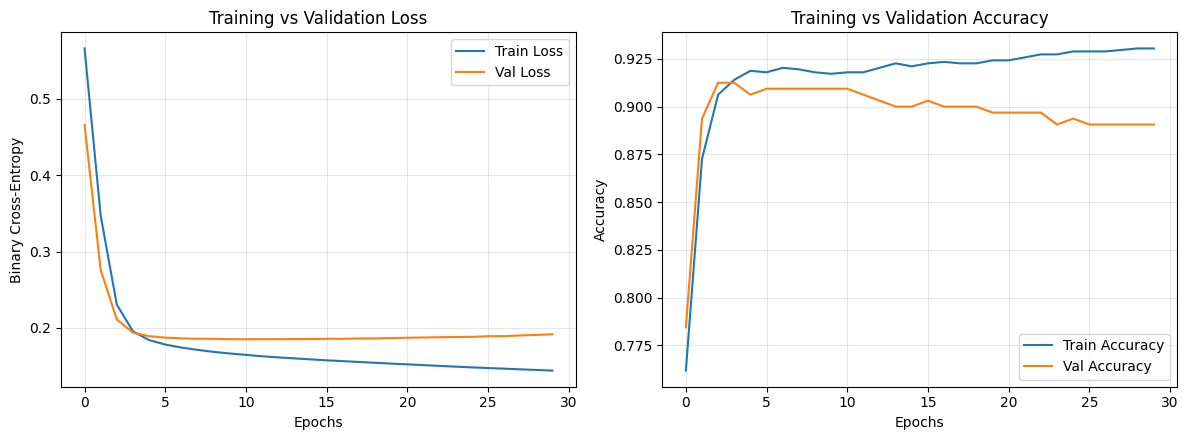


=== Test Set Evaluation (64-32-16 MLP) ===
Accuracy : 0.9100
Precision: 0.8455
Recall   : 0.8304
F1 Score : 0.8378


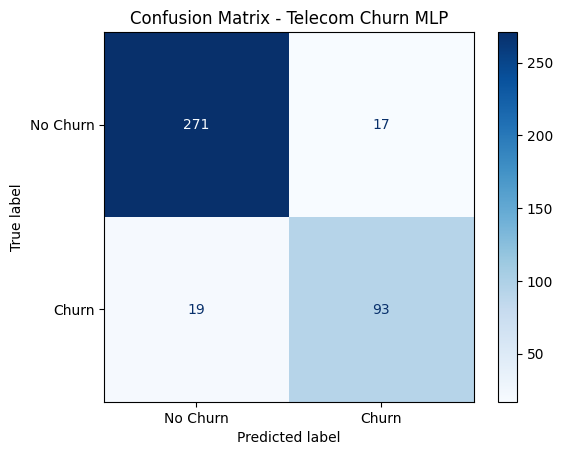


=== Hidden-Layer Width Comparison ===
Hidden Layers  Params  Train Acc  Val Acc  Test Acc  Test F1
       (8, 4)     105     0.9234   0.9062    0.9125   0.8430
     (32, 16)     801     0.9258   0.9094    0.9175   0.8493
 (64, 32, 16)    3137     0.9320   0.9000    0.9100   0.8364
(128, 64, 32)   11393     0.9359   0.8969    0.9025   0.8251


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# ==========================================
# Generate Telecom Customer Churn Dataset
# ==========================================
n_samples = 2000
tenure = np.random.randint(1, 73, n_samples)
monthly_charges = np.round(np.random.uniform(20, 120, n_samples), 2)
contract_type = np.random.choice(["Month-to-Month", "One-Year", "Two-Year"], n_samples, p=[0.5, 0.25, 0.25])
complaints = np.random.poisson(1.2, n_samples)
data_usage = np.round(np.random.uniform(1, 50, n_samples), 2)

# Non-linear churn probability logic
contract_risk = np.where(contract_type == "Month-to-Month", 1.2, np.where(contract_type == "One-Year", -0.4, -1.2))
logits = (
    -0.04 * tenure
    + 0.025 * monthly_charges
    + contract_risk
    + 0.65 * complaints
    - 0.02 * data_usage
    - 1.8
    + np.random.normal(0, 0.5, n_samples)
)
probs = 1 / (1 + np.exp(-logits))
churn = (probs > 0.5).astype(int)

df = pd.DataFrame({
    "tenure": tenure,
    "monthly_charges": monthly_charges,
    "contract_type": contract_type,
    "complaints": complaints,
    "data_usage": data_usage,
    "churn": churn
})

print("Dataset Preview:")
print(df.head(), "\n")
print("Churn Distribution:\n", df["churn"].value_counts(), "\n")

# ==========================================
# Task 1: Pre-process Data (Encode & Scale)
# ==========================================
X = df.drop("churn", axis=1)
y = df["churn"].values

num_cols = ["tenure", "monthly_charges", "complaints", "data_usage"]
cat_cols = ["contract_type"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(sparse_output=False), cat_cols)
])

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

# ==========================================
# Task 2: Build MLP (ReLU hidden, Sigmoid output)
# ==========================================
def build_mlp(input_dim, widths=(64, 32, 16)):
    model = keras.Sequential([layers.Input(shape=(input_dim,))])
    for w in widths:
        model.add(layers.Dense(w, activation="relu"))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return model

# ==========================================
# Task 3: Train & Plot Training/Validation Curves
# ==========================================
mlp = build_mlp(X_train.shape[1], widths=(64, 32, 16))
mlp.summary()

history = mlp.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=30,
    batch_size=32,
    verbose=0
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(history.history["loss"], label="Train Loss")
axes[0].plot(history.history["val_loss"], label="Val Loss")
axes[0].set_title("Training vs Validation Loss")
axes[0].set_xlabel("Epochs")
axes[0].set_ylabel("Binary Cross-Entropy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history.history["accuracy"], label="Train Accuracy")
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy")
axes[1].set_title("Training vs Validation Accuracy")
axes[1].set_xlabel("Epochs")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ==========================================
# Task 4: Report Metrics & Confusion Matrix
# ==========================================
y_pred = (mlp.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f"\n=== Test Set Evaluation (64-32-16 MLP) ===")
print(f"Accuracy : {acc:.4f}")
print(f"Precision: {prec:.4f}")
print(f"Recall   : {rec:.4f}")
print(f"F1 Score : {f1:.4f}")

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["No Churn", "Churn"])
disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Telecom Churn MLP")
plt.show()

# ==========================================
# Task 5: Vary Hidden-Layer Width & Compare
# ==========================================
width_configs = [
    (8, 4),
    (32, 16),
    (64, 32, 16),
    (128, 64, 32)
]

results = []
for cfg in width_configs:
    tf.random.set_seed(42)
    m = build_mlp(X_train.shape[1], widths=cfg)
    h = m.fit(X_train, y_train, validation_split=0.2, epochs=30, batch_size=32, verbose=0)
    preds = (m.predict(X_test, verbose=0).ravel() >= 0.5).astype(int)
    results.append({
        "Hidden Layers": str(cfg),
        "Params": m.count_params(),
        "Train Acc": round(h.history["accuracy"][-1], 4),
        "Val Acc": round(h.history["val_accuracy"][-1], 4),
        "Test Acc": round(accuracy_score(y_test, preds), 4),
        "Test F1": round(f1_score(y_test, preds), 4)
    })

results_df = pd.DataFrame(results)
print("\n=== Hidden-Layer Width Comparison ===")
print(results_df.to_string(index=False))